# 3-BODY PROBLEM AND LAGRANGE POINTS

In [1]:
from matplotlib import pyplot as plt
from matplotlib.animation import PillowWriter
import numpy as np

## Set System

In [2]:
#work in astronomical unit, solar mass and Earth year units

G = 4.*np.pi**2.
m1 = 0.75 #sun would be 1
m2 = 0.25 #this is earth 2.98861*10**-6
M = m1 + m2
mu = m1*m2/M
a = 1. #this is a1 + a2
e =  0. #for Lagrange points, need to assume e = 0. true value is 0.0167086 for earth and code is designed for arbitrary e < 1

$$ v_2 - v_1 = v_{rel}$$
$$ v_2 = v_{rel} + v_1$$

$$ m_1 v_1 + m_2 v_2 = 0 $$
$$ m_1 v_1 + m_2 v_{rel} + m_2 v_1  = 0$$
$$ v_1 = -m_2 v_{rel}/(m_1 + m_2)$$
$$ v_2 = m_1 v_{rel}/(m_1 + m_2)$$

In [3]:


#relative velocity at initial point
vrel = np.sqrt(G*M*(2/(a*(1-e)) - 1/a)) #when e=0, v=sqrt(GM/r)

tmax = 5 #no of years to simulate
dt = 0.001
t = np.linspace(0,tmax,int(tmax/dt + 1))

x1 = np.zeros(len(t))
y1 = np.zeros(len(t))
vx1 = np.zeros(len(t))
vy1 = np.zeros(len(t))

x1[0] = -m2*a*(1-e)/M
y1[0] = 0.
vx1[0] = 0.
vy1[0] = -m2*vrel/M


x2 = np.zeros(len(t))
y2 = np.zeros(len(t))
vx2 = np.zeros(len(t))
vy2 = np.zeros(len(t))

x2[0] = m1*a*(1-e)/M
y2[0] = 0.
vx2[0] = 0.
vy2[0] = m1*vrel/M

x3 = np.zeros(len(t))
y3 = np.zeros(len(t))
vx3 = np.zeros(len(t))
vy3 = np.zeros(len(t))

x_L4 = x1[0] + a/2
y_L4 = np.sqrt(3)*a/2

x_L5 = x_L4
y_L5 = -y_L4

#assumption that e = 0
x3[0] = x_L4
y3[0] = y_L4

vx3[0] = -2*np.pi*(y3[0])
vy3[0] = 2*np.pi*(x3[0])





## Find Lagrange Points 1,2,3

In [4]:
f_L1 = lambda  x1, x2, x3: x3*(x3**4 + (-2*x2 - 2*x1)*x3**3 + (x2**2 + x1**2 + 4*x1*x2)*x3**2 + (-2*x2*x1**2 -2*x1*x2**2)*x3 + x1**2*x2**2) - (m1 - m2)*x3**2 - (-2*m1*x2 + 2*m2*x1)*x3 - (m1*x2**2 - m2*x1**2)

f_L2 = lambda  x1, x2, x3: x3*(x3**4 + (-2*x2 - 2*x1)*x3**3 + (x2**2 + x1**2 + 4*x1*x2)*x3**2 + (-2*x2*x1**2 -2*x1*x2**2)*x3 + x1**2*x2**2) - (m1 + m2)*x3**2 - (-2*m1*x2 - 2*m2*x1)*x3 - (m1*x2**2 + m2*x1**2)

f_L3 = lambda  x1, x2, x3: -x3*(x3**4 + (-2*x2 - 2*x1)*x3**3 + (x2**2 + x1**2 + 4*x1*x2)*x3**2 + (-2*x2*x1**2 -2*x1*x2**2)*x3 + x1**2*x2**2) - (m1 + m2)*x3**2 - (-2*m1*x2 - 2*m2*x1)*x3 - (m1*x2**2 + m2*x1**2)

f_der_L1 = lambda x1, x2, x3: 5*x3**4 + (-2*x2 - 2*x1)*4*x3**3 + (x2**2 + x1**2 + 4*x1*x2)*3*x3**2 + (-2*x2*x1**2 -2*x1*x2**2)*2*x3 + x1**2*x2**2 - (m1 - m2)*2*x3 - (-2*m1*x2 + 2*m2*x1) 

f_der_L2 = lambda x1, x2, x3: 5*x3**4 + (-2*x2 - 2*x1)*4*x3**3 + (x2**2 + x1**2 + 4*x1*x2)*3*x3**2 + (-2*x2*x1**2 -2*x1*x2**2)*2*x3 + x1**2*x2**2 - (m1 + m2)*2*x3 - (-2*m1*x2 - 2*m2*x1) 

f_der_L3 = lambda x1, x2, x3: -5*x3**4 + (-2*x2 - 2*x1)*-4*x3**3 + (x2**2 + x1**2 + 4*x1*x2)*-3*x3**2 + (-2*x2*x1**2 -2*x1*x2**2)*-2*x3 + x1**2*x2**2*-1 - (m1 + m2)*2*x3 - (-2*m1*x2 - 2*m2*x1) 


def newton_raphson(f, fprime, x0, n):
    x = x0

    for i in range(0, n):
        x = x - f(x1[0], x2[0], x)/fprime(x1[0], x2[0], x)
    
    return x, f(x1[0], x2[0], x)

In [5]:
newton_raphson(f_L1, f_der_L1, 0.5*a, 50)

(0.3607434283670166, 0.0)

In [6]:
x_L1 = 0.3607434283670166
y_L1  = 0.

In [7]:
m1/(0.3607434283670166 - x1[0])**2 - m2/(0.3607434283670166 - x2[0])**2, 0.3607434283670166

(0.36074342836701656, 0.3607434283670166)

In [8]:
newton_raphson(f_L2, f_der_L2, 1.5*a, 50)

(1.2658581025103504, 3.3306690738754696e-16)

In [9]:
x_L2 = 1.2658581025103504
y_L2  = 0.

In [10]:
m1/(1.2658581025103504 - x1[0])**2 + m2/(1.2658581025103504 - x2[0])**2, 1.2658581025103504

(1.2658581025103501, 1.2658581025103504)

In [11]:
newton_raphson(f_L3, f_der_L3, -1.5*a, 50)

(-1.1031668488229245, -2.220446049250313e-16)

In [12]:
x_L3 = -1.1031668488229245
y_L3  = 0.

In [13]:
m1/(-1.1031668488229245 - x1[0])**2 + m2/(-1.1031668488229245- x2[0])**2, 1.1031668488229245

(1.1031668488229245, 1.1031668488229245)

## Time Evolve

In [14]:

#Leapfrog/Verlet Symplectic Integrator

for i in range(0, len(t)-1):

    r12 = np.sqrt((x1[i] - x2[i])**2. + (y1[i] - y2[i])**2.)
    r13 = np.sqrt((x1[i] - x3[i])**2. + (y1[i] - y3[i])**2.)
    r23 = np.sqrt((x2[i] - x3[i])**2. + (y2[i] - y3[i])**2.)

    vx1_half = vx1[i] + (G*m2/r12**3)*(x2[i] - x1[i])*(dt/2)
    vy1_half = vy1[i] + (G*m2/r12**3)*(y2[i] - y1[i])*(dt/2)

    vx2_half = vx2[i] + (G*m1/r12**3)*(x1[i] - x2[i])*(dt/2)
    vy2_half = vy2[i] + (G*m1/r12**3)*(y1[i] - y2[i])*(dt/2)

    vx3_half = vx3[i] + (G*m1/r13**3)*(x1[i] - x3[i])*(dt/2) + (G*m2/r23**3)*(x2[i] - x3[i])*(dt/2)
    vy3_half = vy3[i] + (G*m1/r13**3)*(y1[i] - y3[i])*(dt/2) + (G*m2/r23**3)*(y2[i] - y3[i])*(dt/2)

    x1[i+1] = x1[i] + vx1_half*dt
    y1[i+1] = y1[i] + vy1_half*dt
    x2[i+1] = x2[i] + vx2_half*dt
    y2[i+1] = y2[i] + vy2_half*dt
    x3[i+1] = x3[i] + vx3_half*dt
    y3[i+1] = y3[i] + vy3_half*dt

    r12 = np.sqrt((x1[i+1] - x2[i+1])**2. + (y1[i+1] - y2[i+1])**2.)
    r13 = np.sqrt((x1[i+1] - x3[i+1])**2. + (y1[i+1] - y3[i+1])**2.)
    r23 = np.sqrt((x2[i+1] - x3[i+1])**2. + (y2[i+1] - y3[i+1])**2.)

    vx1[i+1] = vx1_half + (G*m2/r12**3)*(x2[i+1] - x1[i+1])*(dt/2)
    vy1[i+1] = vy1_half + (G*m2/r12**3)*(y2[i+1] - y1[i+1])*(dt/2)
    
    vx2[i+1] = vx2_half + (G*m1/r12**3)*(x1[i+1] - x2[i+1])*(dt/2)
    vy2[i+1] = vy2_half + (G*m1/r12**3)*(y1[i+1] - y2[i+1])*(dt/2)

    vx3[i+1] = vx3_half + (G*m1/r13**3)*(x1[i+1] - x3[i+1])*(dt/2) + (G*m2/r23**3)*(x2[i+1] - x3[i+1])*(dt/2)
    vy3[i+1] = vy3_half + (G*m1/r13**3)*(y1[i+1] - y3[i+1])*(dt/2) + (G*m2/r23**3)*(y2[i+1] - y3[i+1])*(dt/2)


    

In [15]:
#Check conservation

E = (1/2)*m1*(vx1**2. + vy1**2.) + (1/2)*m2*(vx2**2. + vy2**2.) - G*m1*m2/np.sqrt((x2-x1)**2 + (y2 - y1)**2)

Px = m1*vx1 + m2*vx2

Py = m1*vy1 + m2*vy2

L = m1*(x1*vy1 - y1*vx1) + m2*(x2*vy2 - y2*vx2)

#Check C.O.M

x_COM = (m1*x1 + m2*x2)/M

y_COM = (m1*y1 + m2*y2)/M

C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_17152\65898484.py:2: RuntimeWarning: divide by zero encountered in log10
  plt.plot(t, np.log10(np.abs(Px)), label =r'$P_x$')
C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_17152\65898484.py:3: RuntimeWarning: divide by zero encountered in log10
  plt.plot(t, np.log10(np.abs(Py)), label =r'$P_y$')
C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_17152\65898484.py:5: RuntimeWarning: divide by zero encountered in log10
  plt.plot(t, np.log10(np.abs(x_COM)), label =r'$x_{COM}$')
C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_17152\65898484.py:6: RuntimeWarning: divide by zero encountered in log10
  plt.plot(t, np.log10(np.abs(y_COM)), label =r'$y_{COM}$')


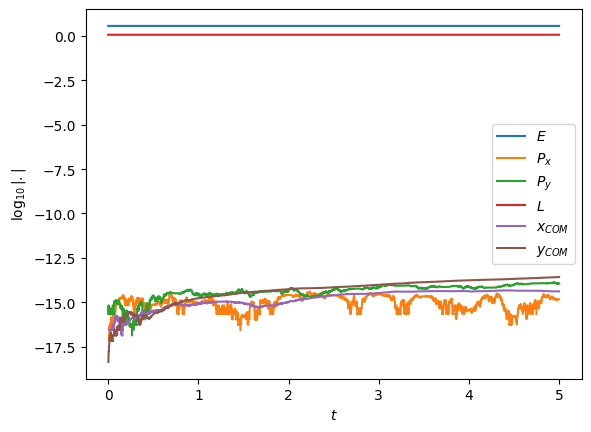

In [16]:
plt.plot(t, np.log10(np.abs(E)), label =r'$E$')
plt.plot(t, np.log10(np.abs(Px)), label =r'$P_x$')
plt.plot(t, np.log10(np.abs(Py)), label =r'$P_y$')
plt.plot(t, np.log10(np.abs(L)), label =r'$L$')
plt.plot(t, np.log10(np.abs(x_COM)), label =r'$x_{COM}$')
plt.plot(t, np.log10(np.abs(y_COM)), label =r'$y_{COM}$')
plt.xlabel(r'$t$')
plt.ylabel(r'$\log_{10}|.|$')
plt.legend()
plt.show()

## Make Movie

In [ ]:
def plot_frame_and_potential(index, ax):

    if x2[index]<x1[index]: 
        x_vals = np.concatenate((np.linspace(-1.5, x2[index]-0.01, 100), 
                                 np.linspace(x2[index]+0.01, x1[index]-0.01, 100), 
                                 np.linspace(x1[index]+0.01, 1.5, 100))) 
    else: 
        x_vals = np.concatenate((np.linspace(-1.5, x1[index]-0.01, 100), 
                                 np.linspace(x1[index]+0.01, x2[index]-0.01, 100), 
                                 np.linspace(x2[index]+0.01, 1.5, 100))) 
    if y2[index]<y1[index]: 
        y_vals = np.concatenate((np.linspace(-1.5, y2[index]-0.01, 100), 
                                 np.linspace(y2[index]+0.01, y1[index]-0.01, 100), 
                                 np.linspace(y1[index]+0.01, 1.5, 100))) 
    else: y_vals = np.concatenate((np.linspace(-1.5, y1[index]-0.01, 100), 
                                   np.linspace(y1[index]+0.01, y2[index]-0.01, 100), 
                                   np.linspace(y2[index]+0.01, 1.5, 100))) 
    X_vals,Y_vals = np.meshgrid(x_vals, y_vals ) 

    Phi_eff = (
    -G*m1/np.sqrt((X_vals-x1[index])**2 + (Y_vals-y1[index])**2)
    -G*m2/np.sqrt((X_vals-x2[index])**2 + (Y_vals-y2[index])**2)
    -0.5*(4*np.pi**2)*((X_vals-x_COM[0])**2 + (Y_vals-y_COM[0])**2)
)
    
    ax.pcolormesh(X_vals, Y_vals,Phi_eff , vmin=-75 ) 

    theta = 2*np.pi*t[index]

    x_L1_rot, y_L1_rot = np.cos(theta)*x_L1 - np.sin(theta)*y_L1, np.sin(theta)*x_L1 + np.cos(theta)*y_L1

    x_L2_rot, y_L2_rot = np.cos(theta)*x_L2 - np.sin(theta)*y_L2, np.sin(theta)*x_L2 + np.cos(theta)*y_L2

    x_L3_rot, y_L3_rot = np.cos(theta)*x_L3 - np.sin(theta)*y_L3, np.sin(theta)*x_L3 + np.cos(theta)*y_L3

    x_L4_rot, y_L4_rot = np.cos(theta)*x_L4 - np.sin(theta)*y_L4, np.sin(theta)*x_L4 + np.cos(theta)*y_L4

    x_L5_rot, y_L5_rot = np.cos(theta)*x_L5 - np.sin(theta)*y_L5, np.sin(theta)*x_L5 + np.cos(theta)*y_L5

    ax.plot([ x_L3_rot ,x_L1_rot, x_L2_rot],[y_L3_rot ,y_L1_rot, y_L2_rot],c='white', linestyle='dashed', linewidth = 1)
    ax.plot([ x_L4_rot ,x_L5_rot],[y_L4_rot , y_L5_rot],c='white', linestyle='dashed', linewidth = 1)
    ax.plot([ x1[index] ,x_L4_rot, x2[index], x_L5_rot, x1[index]],[y1[index], y_L4_rot , y2[index],y_L5_rot, y1[index]],c='white', linestyle='dashed', linewidth = 1)
    
    ax.scatter(x3[index],y3[index], c ='red', label=r'$L_4$')
  
    ax.scatter(x2[index],y2[index], c='blue', label =r'$m_2$')
    
    ax.scatter(x1[index],y1[index], c='orange', label =r'$m_1$')
  

    

    ax.scatter(x_L1_rot, y_L1_rot , c='black', marker= 'X')
    ax.scatter(x_L2_rot, y_L2_rot, c='black', marker= 'X')
    ax.scatter(x_L3_rot, y_L3_rot,  c='black', marker= 'X')
    #plt.scatter(, c='black', marker= 'X')
    ax.scatter(x_L5_rot, y_L5_rot,  c='black', marker= 'X')

    ax.annotate(f'Time: {t[index]:.2f} y', (-1.45, 1.45), c='white')

    ax.set_xlim([-1.5,1.5])
    ax.set_ylim([-1.5,1.5])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend()
    
    
    

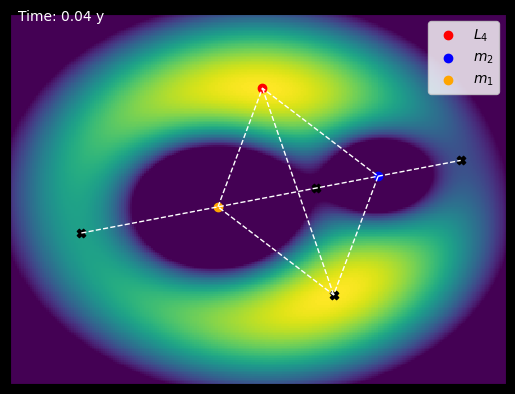

In [56]:
fig, ax = plt.subplots()
fig.patch.set_facecolor('black')
plot_frame_and_potential(40,ax)
plt.show()

In [57]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

C:\Users\Ayush Roy\AppData\Local\Temp\ipykernel_17152\3581137396.py:26: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  ax.pcolormesh(X_vals, Y_vals,Phi_eff , vmin=-75 )


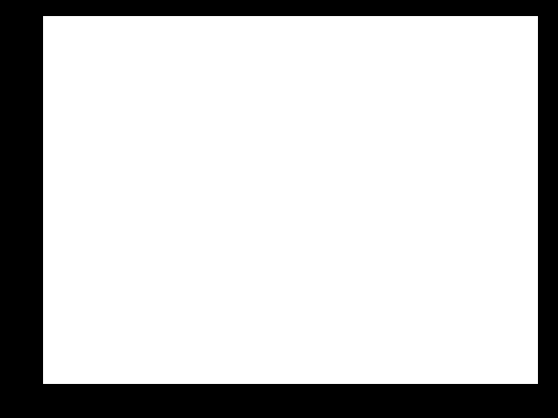

In [59]:
fig, ax = plt.subplots()
fig.patch.set_facecolor('black')

with writer.saving(fig, 'lagrange_points.gif',100):
    for i in range(0, len(t)):
        if i%20 == 0:
            plot_frame_and_potential(i, ax)
            writer.grab_frame()
            ax.clear()
        